# Project Group - 20

Members: 
1) Savino Every
2) Nicholas Johnson
3) Gijs van Vliet
4) Dániel Seesink
5) Delano van den Bosch


# Contribution Statement

*Be specific. Some of the tasks can be coding (expect everyone to do this), background research, conceptualisation, visualisation, data analysis, data modelling*

**Author 1**:

**Author 2**:

**Author 3**:

**Author 4**:

**Author 5**:

# Introduction

## 1.1 Context

context

## 1.2 Problem statement

problem statement

## 1.3 Research Objective & Question

*Requires data modeling and quantitative research in Transport, Infrastructure & Logistics*

Mention & justify the indicators

# Methodology

text

## 2.1 Imports

text

In [ ]:
from background.WIP_train_analysis import (
    load_train_data,
    filter_cancellation_days,
    analyse_delays,
    analyse_delays_per_hour,
    analyse_punctuality,
    analyse_delay_absorption,
    analyse_correlations
)
import importlib
import background.WIP_train_analysis 

importlib.reload(background.WIP_train_analysis )

train = load_train_data()
train = filter_cancellation_days(train, cancellation_percentile=90)

Assumptions:
- Filtering on 90% threshold of cancellations -> cancel day
- Run from 5 to 22

## 2.2 Data Used

Describe data cleaning and modification of both datasets (period_selection.ipynb 1. to 3., except initialisation of delay variables)

## 2.3 Data Pipeline

# Results

## 3.1 Weather analysis

## 3.2 Train analysis - Total period

The train data usage, cleaning and modification is described in section 2.2. For background, see /background/period_selection.ipynb and background/train_analysis.py.

The train analysis creates a baseline for the comparison analysis; an initial data pipeline is created to identify the generic indicators and insights which can be retreived from the data.

**DELAY VS PUNCTUALITY!!!!!**

The three indicators and justification used are as follows:
- Delay indicator: 
    - Every arrival- and departure delay is flagged if the delay column > 0. 
    - An additional binary indicator is more important, however, which is the arrival and departure delay being bigger or equal to three (3) minutes or 180 seconds. This is the delay value indicated in NS' performance agreements as communicated to passengers and stakeholders [1].
- Number of cancellations:
    - A train is cancelled if either arrival or departure is cancelled.
    - Cancellations can be per hour, day, week of day or the average over the analysis period.
- Punctuality performance:
    - Punctuality of a train is the number of on-time events (on-time indicating delays being smaller than 180 seconds) divided by the total scheduled events.
    - Punctuality can differ at arrival, departure and a total punctuality figure.
    - Keeping non-cancrlled trains in this dataset

### 3.2.1 Delays and cancellations in numbers

25.0% of trains were delayed.
9.8% of train operations were delayed by more than 3 minutes (actual delay classification).
9.3% of trains were completely cancelled.
DELAYS AND CANCELLATIONS
Number of complete cancellations: 7919
    25.0% of trains were delayed.
    9.8% of train operations were delayed by at least 3 minutes.
    9.3% of trains were cancelled.

RELATIVE PERFORMANCE
    Delay-minutes per vehicle: 1.22 minutes
    Total delay-minutes per day: 845.5 minutes
    Cancellations per 100 vehicles: 9.29
    Cancellations per day: 64.38


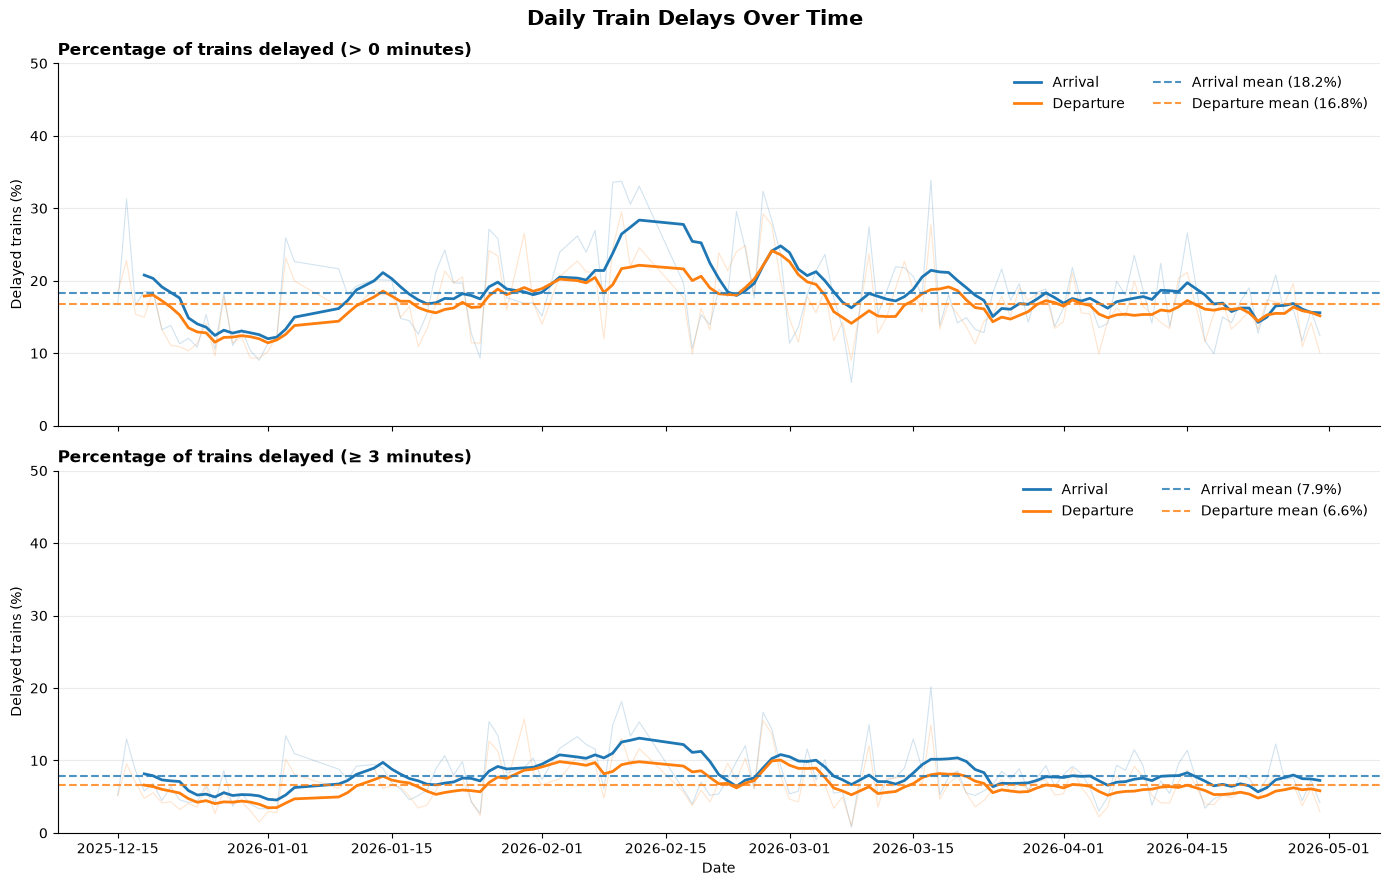

In [76]:
delayed_trains = (len(train[(train['arrival_delayed'] == True) | (train['departure_delayed'] == True)])) / len(train) * 100
delayed_operations = len(train[(train['arrival_delayed_3'] == True) | (train['departure_delayed_3'] == True)]) / len(train) * 100
total_cancellations = len(train[train['cancelled'] == True])
total_cancellations_perct = total_cancellations / len(train) * 100

print(f"{delayed_trains:.1f}% of trains were delayed.")
print(f"{delayed_operations:.1f}% of train operations were delayed by more than 3 minutes (actual delay classification).")
print(f"{total_cancellations_perct:.1f}% of trains were completely cancelled.")

delay = analyse_delays(train)

Across the full period, 25% of the trains experienced a delay greater than zero minutes, while around 10% were delayed by at least three minutes. This indicates that minor delays were relatively common. On average, each vehicle is delayed by 1.22 minutes per vehicle, while the total delay-minutes per day accumualted to 845.5 minutes in the baseline. The cancellations per 100 vehicles in the baseline equals 9.3 vehicles per 100. These results show that operational disruptions involvee both delays and cancellations.

The figure shows the daily percentage of delayed trains in the time-period, for delays above 0 minutes and delays of 3 minutes or more. Thin lines show daily values and bold lines show the smoothed rolling trend. Arrivals are delayed more often than departures (mean 18.2% vs 16.8% for 0 minutes and 7.9% vs 6.6% for above 3 minutes), an early indicator that part of the arrival delay is absorbed during the stop. 

Delays vary over time; the lowest levels occur around the year turnover, after implementation of the new timetable, and are followed by a sustained peak from February to end of February. Here, arrival delays reach around 28% and 13% (>0 min), from about 12% and 5% in December (>= 3 min). The thin lines indicate that delays fluctuate strongly, so the trend is the better indicator along the mean values.

### 3.2.2 Delays per hour

Next, we analyse the average delays, frequency of delays and cacellation rate per hour of operation over the dataset. As indicated earlier, operation is defined as the period from 0500 until 2300 (h= [5,22]).

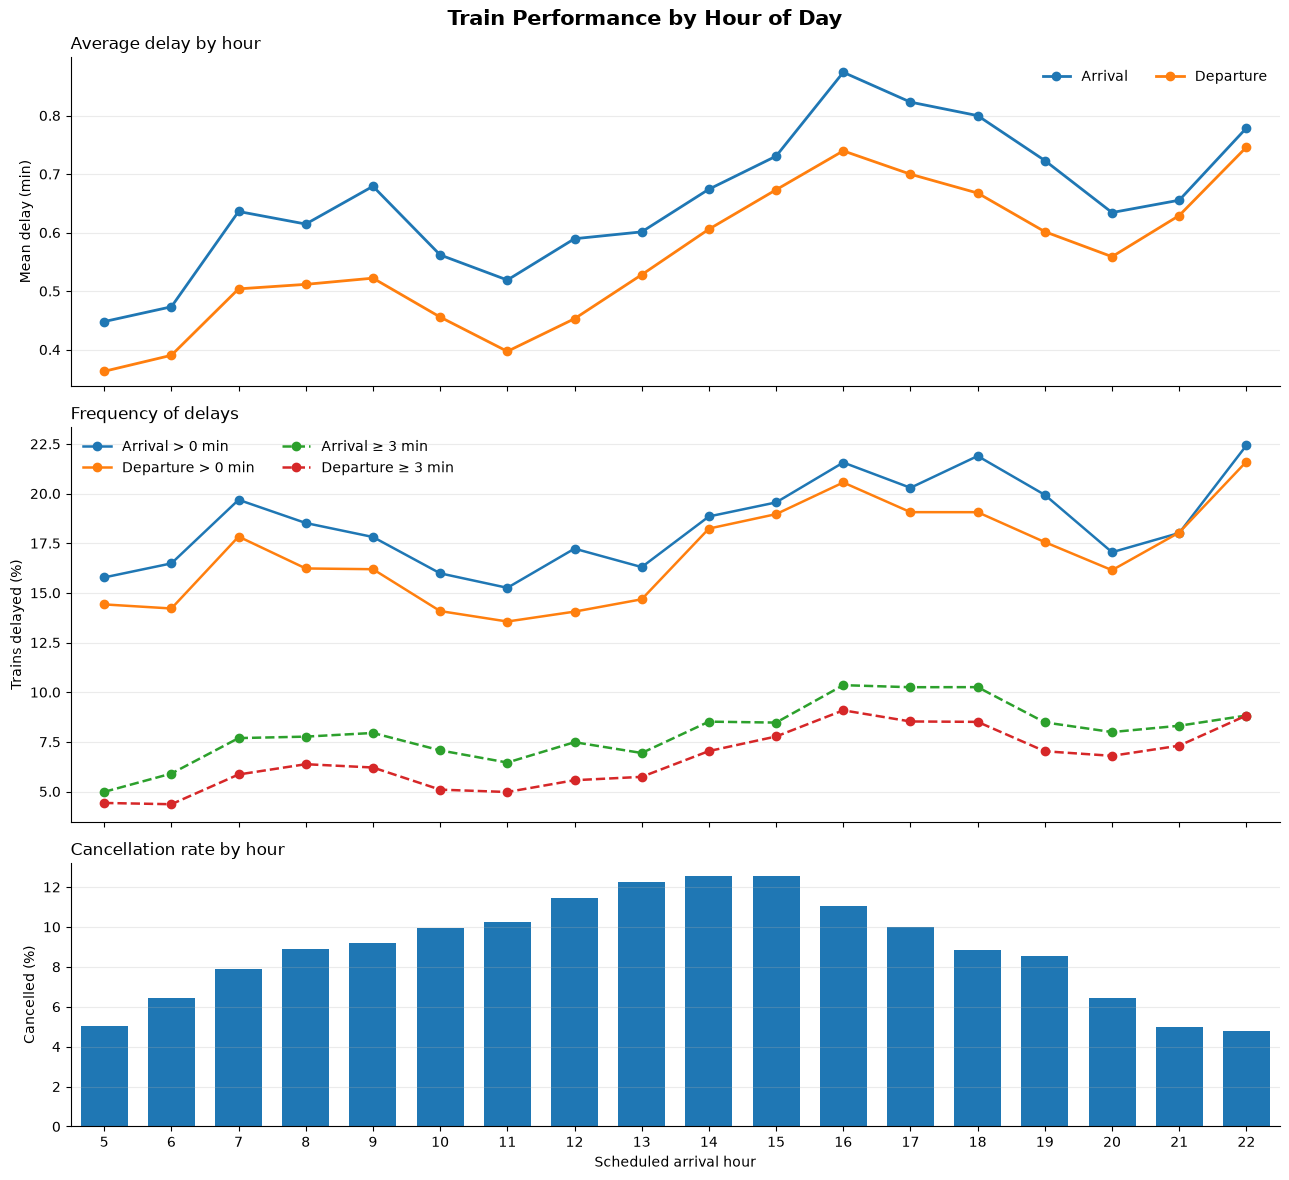

In [77]:
delay_per_hour = analyse_delays_per_hour(train)

The figure shows the mean delay in minutes per hour for arrival and departure, the frequency of delays in percentage for arrival and departure (> 0 min and >= 3 min), as well as the cancellation rate per hour. 

Delays for a clear daily pattern, where mean arrival delay is lowest in the early morning and around midday (0.45 min and 0.52 min), where it especially rises thorugh the afternoon, peaking in the hour of 16:00 - 17:00 with a mean arrival delay of around 0.9 minutes. An additional peak occurs at 22:00 - 23:00. The share of delayed trains show the same shape: arrivals delayed by more than 0 minutes range from about 15% to 22% in a long afternoon/early evening peak. The afternoon peak coincides with the evening rush, suggesting that the delays build up during the day through knock-on effects and higher loads. Departure delays are consistenly lower than arrivals, in both mean delay and frequency, which again indicate delay absorption during stops using dwell times. 

The cancellation rate  follows a different pattern; it seems so build up into the afternoon and decreases before the evening rush. Canceallations peak before delay peak hours. A possible explanation is that cancellations are used to prevent propagation or reflect off-peak adjustments, although this is not concluded from the figure.

### 3.2.3 Punctuality

Punctuality discarded cancellations in the dataset; cancelled trains cannot be punctual.

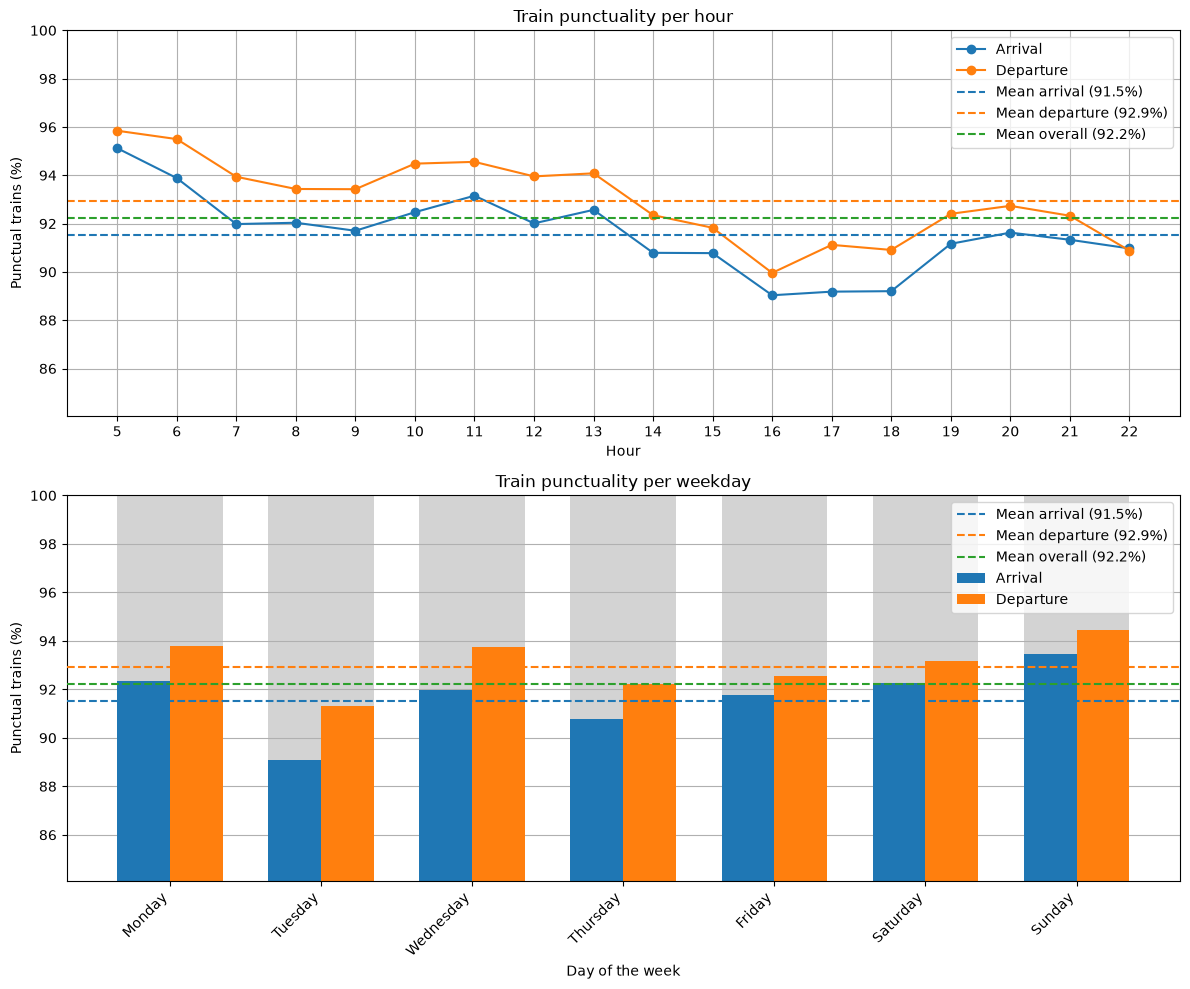

Trains punctual at both arrival and departure: 89.85%
Trains punctual at arrival: 91.53%
Trains punctual at departure: 92.94%


In [78]:
analyse_punctuality(train)

The plot shows train punctuality by hour of day and weekday. Departures are more punctual thamn arrivals in (nearly) all hours and on all days (mean 92.9% vs 91.5%), indicating possible delay absorption stops.

Punctuality is highest in the early morning between 05:00 and 06:00 and lowest in the afternoon rush-peak between 16:00 and 19:00, with arrival punctuality dropping to around 89%. In the evening, little delay is recovered. Across the week, Tuesday is the least punctual day in the baseline (~89% on arrival and ~91% on departure), whereas Sunday is the most punctual. Weekend days generally perform better than weekdays. The smallest arrival-departure gap is on Friday, and highest on Tuesdays.

At train level, of the almost 9000 trains with a delay at arrival of departure, 54% are delayed at both, 30% are delayed only at arrival and 17% are delayed only at departure, generating delay. Of all delayed arrivals, about 36% are recovered before departure.

Train punctuality of departures is consistently higher than punctuality at arrivals; the mean values confirm this. This is cause for the investigation of delay absorption of Utrecht Centraal.

### 3.2.4 Delay absorption and propagation

Mean net delay change (all non-cancelled trains): -0.08 min/train
Mean net delay change (selected trains): -0.32 min/train
Maximum delay increase: -31.0 minutes
Maximum delay reduction: 8.0 minutes
Overall delay absorption: 12.22%
Net delay change: -0.32 min/train
Late-arrival delay absorption: 31.02%


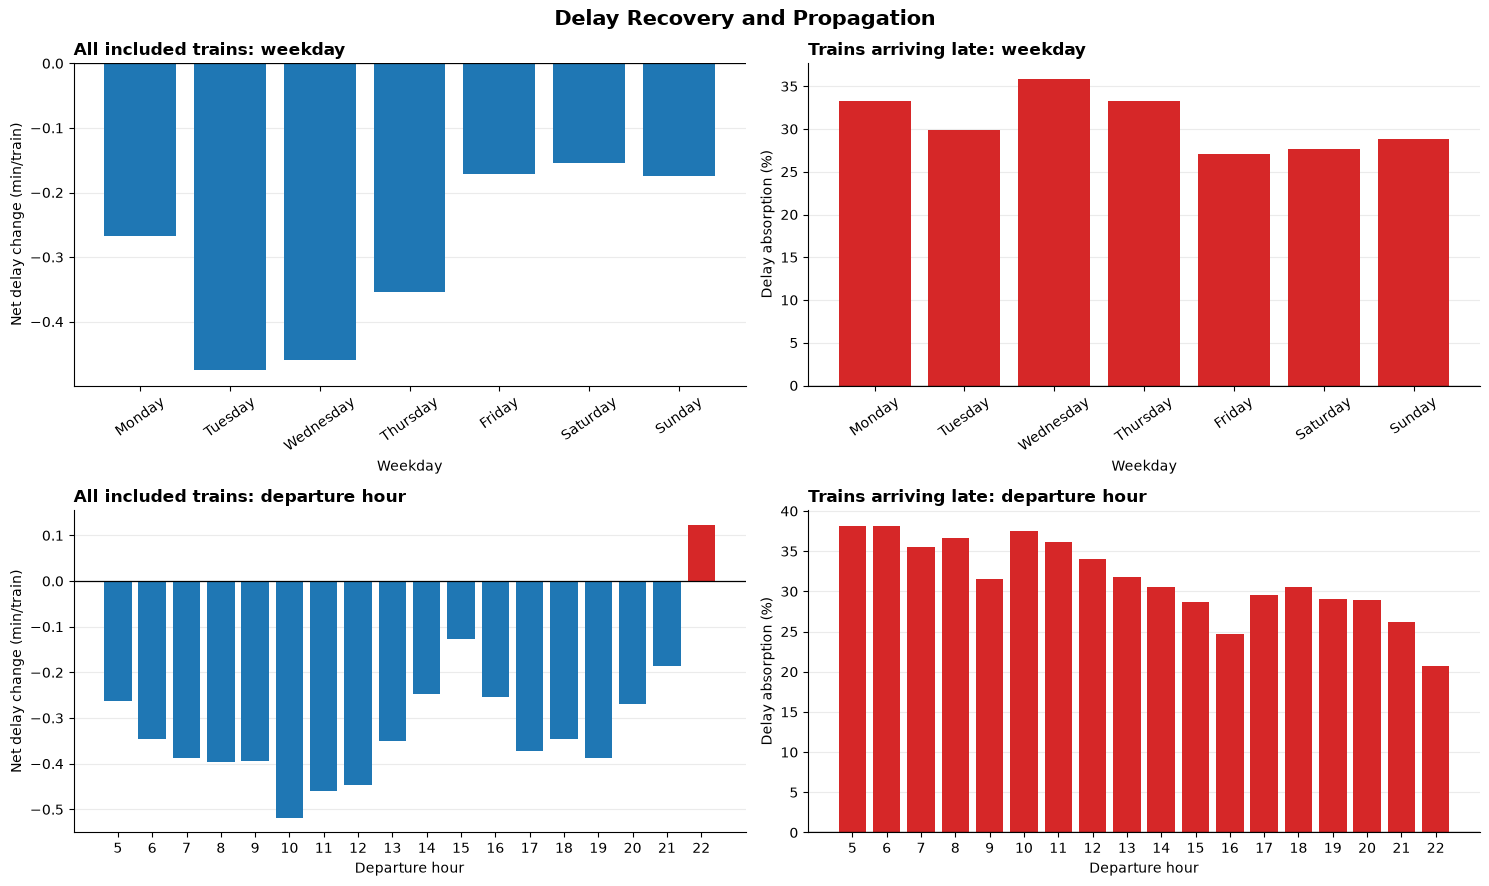

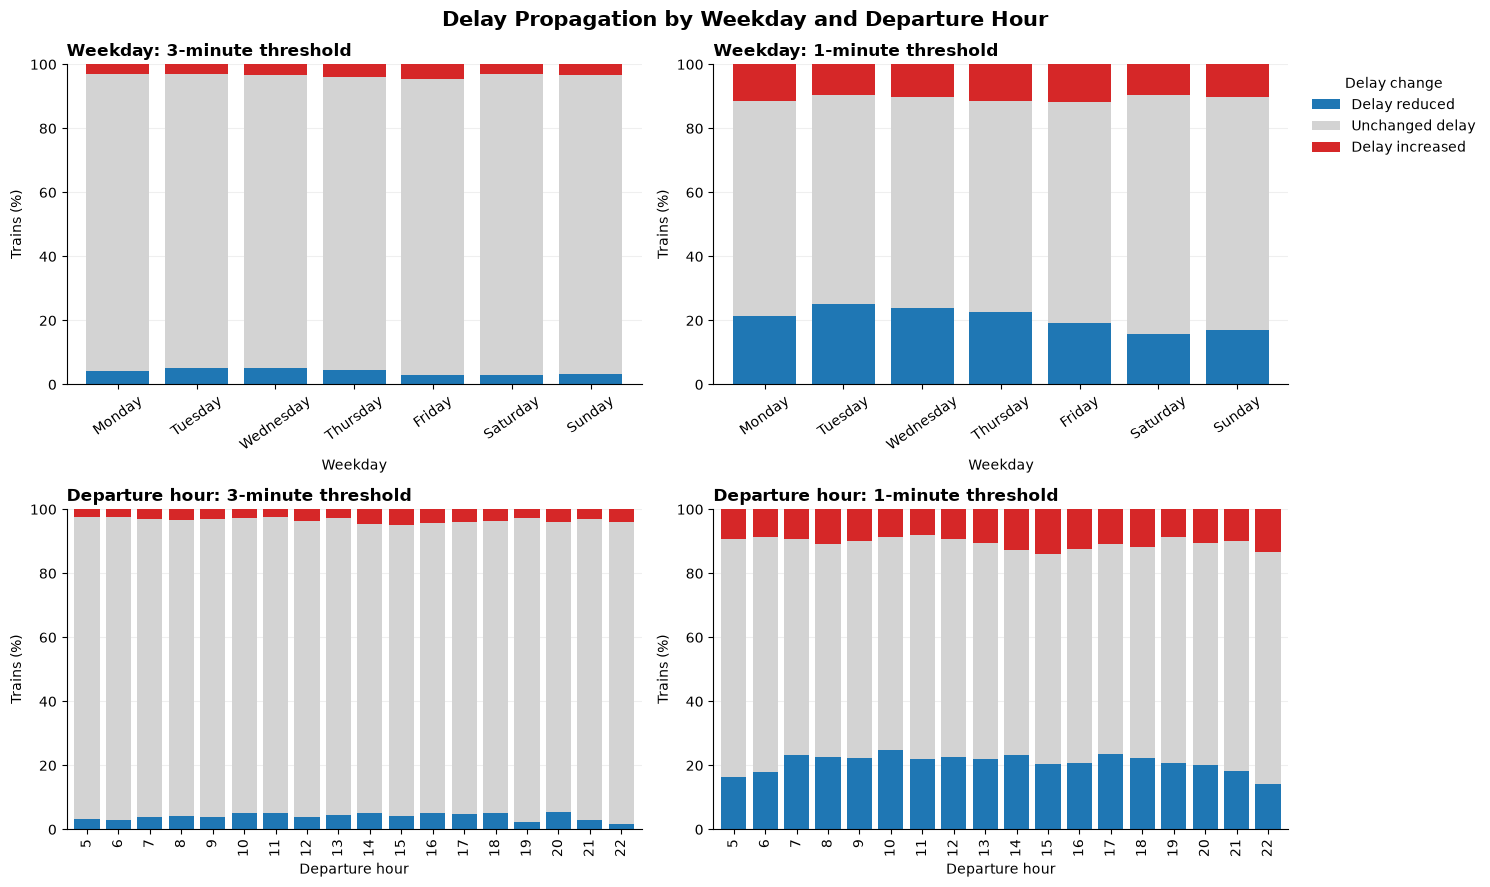

In [79]:
analyse_delay_absorption(train)

### 3.2.3 Correlation and dwell-time heatmaps

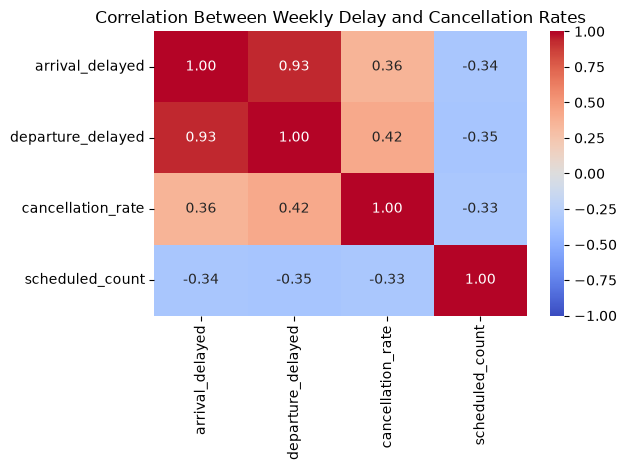

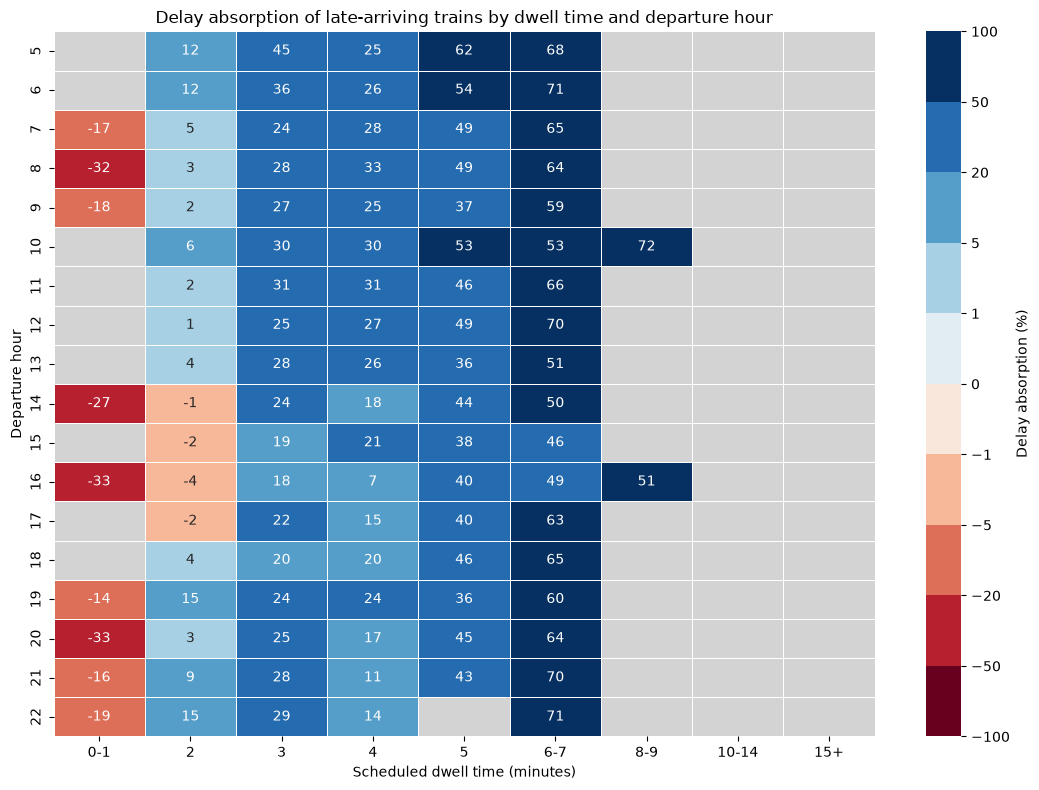

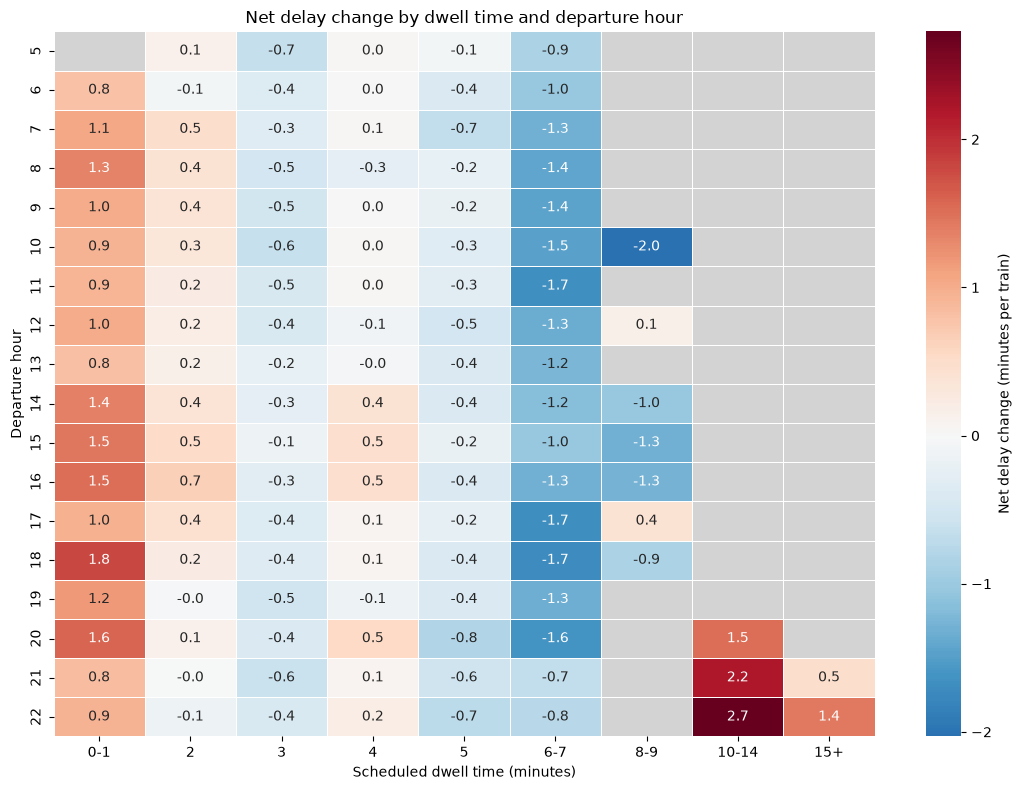

In [80]:
analyse_correlations(train)

Recognize difference between delay and punctuality

## 3.3 Train analysis - Selected period

Same as above

## 3.4 Comparison analysis

# Conclusion

# Discussion

### AI Statement:

We, as a group, acknowledge the use of ChatGPT and Claude in preparing this submission. We used it for the following purposes:
- Brainstorming ahead of team meetings
- Concatenating data flows after creation (e.g. having AI assist to create a code which was in a .ipynb to convert to a .py after validation to use as an import definition)
    - In specific, train_analysis.py was created using chatGPT where period_selection.ipynb was its input with the initial prompt to create runnable definitions per sub-section.
- Providing feedback/advice on how to improve the basic matplotlib plots (...)
- ...

We confirm that we have critically reviewed and verfied all AI-assisted content per part used and that the submitted work reflects our own understanding according to the task division. We take full responsibility for the accuracy and orginality of the combination of AI usage and project applicance.

# Sources

[1] https://nsannualreport.nl/annual-report-2025/performance-what-we-have-achieved/our-operations/performance-agreements